# Report 4 — Mô hình phân loại: video đăng giờ nào thì lọt Top Trending?

**Câu hỏi:** đăng video trong **giờ hành chính** (08:00–16:59, thứ 2–6, giờ VN) hay **giờ nghỉ** thì dễ lọt chart `mostPopular` VN trong 72 giờ đầu hơn?

- **H₀:** khả năng lọt trending của video đăng giờ hành chính **bằng** video đăng giờ nghỉ, khi đã kiểm soát ngày đăng, quy mô kênh, thể loại và thời lượng.
- **H₁:** hai khả năng này **khác nhau**.

**Quy tắc kết luận (chốt trước khi chạy, `docs/TEAM_HANDOVER_REPORT4.md` mục 2):**
1. **Logistic Regression (LR)** quyết định: odds ratio (OR) giờ nghỉ / giờ hành chính trong mô hình đủ kiểm soát (bộ feature C). CI 95% bootstrap theo kênh **không chứa 1** → bác bỏ H₀; **chứa 1** → chưa đủ bằng chứng bác bỏ H₀.
2. **XGBoost** kiểm tra độ vững: PR-AUC của bộ C so với bộ C bỏ biến thời gian. Cùng chiều với LR → kết luận vững; ngược chiều → yếu.

**Bố cục:** Phần 1 — Logistic Regression và kết luận H₀ (BanNH) · Phần 2 — XGBoost (phat: huấn luyện; duc: giải thích) · Phần 3 — So sánh mô hình trên tập test (duc) · Phần 4 — Kết luận chung (BanNH).

Dữ liệu: bản đóng băng `data/processed/video_features_full_2026-11-01.csv` (không commit). Code dùng chung: `src/modeling/split.py` (tách train/test), `src/modeling/features.py` (feature), `src/modeling/logistic.py` (LR).

In [1]:
import sys, warnings
from pathlib import Path

# Cho phép import src.* khi mở notebook từ thư mục notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.modeling.split import doc_tap_sach, tach_train_test, loc_co_kha_nang, tom_tat, FILE_KENH_TEST
from src.modeling.features import (them_bien, kiem_tra_cot_cam, BO_A_LR, BO_B_LR, DANH_MUC_DAY_DU,
                                   KHUNG_NGAY_THUONG, COT_CAM)
from src.modeling import logistic as lg

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
N_BOOT, N_BOOT_PHU = 500, 300   # số lần bootstrap theo kênh: mô hình chính / các kiểm tra phụ

## Phần 1 — Logistic Regression (BanNH)

### 1.1 Tập dữ liệu và tách train / test

- **Tập chính** = `is_clean` bỏ **Shorts** (`is_short`, ≤ 3 phút), **Tin tức và Chính trị**, **Thể thao**. Ba nhóm này gần như không bao giờ lên chart chính (EDA D2: Shorts 5/23.093, Tin tức 0/9.632, Thể thao 0/3.021), nên giữ lại chỉ làm loãng phép so sánh khung giờ. Đây là nhóm "video có khả năng trending" của EDA D5.
- **Tập đầy đủ** `is_clean` chỉ dùng để kiểm tra độ vững (mục 1.5).
- **Tách theo kênh:** `StratifiedGroupKFold(5, random_state=42)` theo `channel_id` trên toàn bộ `is_clean`, fold đầu làm test; danh sách kênh test đã cố định ở `data/processed/test_channels.csv`. Video cùng kênh luôn nằm cùng phía, nên mô hình không thể "nhớ kênh". Tập test chỉ chấm **một lần** ở mục 1.6.

In [2]:
df_all = doc_tap_sach()                                   # toàn bộ is_clean
train_full, test_full = tach_train_test(df_all)           # theo kênh test đã cố định
train = them_bien(loc_co_kha_nang(train_full))            # tập chính
test = them_bien(loc_co_kha_nang(test_full))
assert not set(train["channel_id"]) & set(test["channel_id"]), "kênh nằm ở cả train và test"
y_train, y_test = train["is_trending_main"].astype(int).to_numpy(), test["is_trending_main"].astype(int).to_numpy()

pd.concat([tom_tat(train_full, test_full).assign(tap_du_lieu="Đầy đủ is_clean"),
           tom_tat(train, test).assign(tap_du_lieu="Chính: có khả năng trending")]).set_index(["tap_du_lieu", "tap"])

so_video  so_kenh  so_trending  ti_le_trending  pct_hanh_chinh
tap_du_lieu                 tap                                                                  
Đầy đủ is_clean             train     32423     2681          318            0.98            34.8
                            test       8108      675           80            0.99            36.8
Chính: có khả năng trending train      8152     1100          315            3.86            29.2
                            test       2079      291           78            3.75            29.1

### 1.2 Feature

| Bộ | Cột | Ghi chú |
|---|---|---|
| **A** — thời gian | `time_slot` | Một biến nhị phân để có đúng một OR |
| **B** — kiểm soát | `ngay` (ngày ra mắt, 14 mức), `log10_subs`, `cat_gop` (Blog, Giải trí, Âm nhạc, Trò chơi, Khác), `duration_group` (4 mức, đã bỏ ≤ 3 phút), `is_live_or_premiere`, `title_length`, `n_tags` | Theo EDA D3 |
| **C** = A + B | | Bộ dùng để kết luận H₀ |

- Cột phân loại được one-hot, **bỏ mức đầu theo bảng chữ cái làm mức tham chiếu**: `time_slot` → `hanh_chinh`; `ngay` → 25/09; `cat_gop` → Giải trí; `duration_group` → 10–20 phút. Cột số được chuẩn hoá.
- Các cột lộ nhãn hoặc cột làm sạch bị chặn bằng `kiem_tra_cot_cam()` (`COT_CAM` trong `features.py`).
- 3 video ra mắt 23:53 ngày 24/09 được gộp vào 25/09.

In [3]:
BO_C = BO_A_LR + BO_B_LR
kiem_tra_cot_cam(BO_C)
print("Bộ A:", BO_A_LR)
print("Bộ B:", BO_B_LR)
print("Cột cấm:", COT_CAM)
X_mau, _ = lg.ma_tran(train, BO_C)
print(f"\nBộ C sau one-hot + chuẩn hoá: {X_mau.shape[1]} cột")
print(list(X_mau.columns))

Bộ A: ['time_slot']
Bộ B: ['ngay', 'log10_subs', 'cat_gop', 'duration_group', 'is_live_or_premiere', 'title_length', 'n_tags']
Cột cấm: ('is_trending_main', 'hours_to_trending_main', 'best_rank_main', 'is_trending_category', 'hours_to_trending_category', 'best_rank_category', 'coverage_24h', 'coverage_72h', 'coverage_cat_24h', 'coverage_cat_72h', 'flag_no_duration', 'flag_hidden_subs', 'flag_extreme_duration', 'flag_low_coverage', 'flag_low_coverage_cat', 'is_clean', 'is_clean_category', 'video_id', 'channel_id')

Bộ C sau one-hot + chuẩn hoá: 25 cột
['time_slot_nghi', 'ngay_2026-09-26', 'ngay_2026-09-27', 'ngay_2026-09-28', 'ngay_2026-09-29', 'ngay_2026-09-30', 'ngay_2026-10-01', 'ngay_2026-10-02', 'ngay_2026-10-03', 'ngay_2026-10-04', 'ngay_2026-10-05', 'ngay_2026-10-10', 'ngay_2026-10-12', 'ngay_2026-10-19', 'cat_gop_Khác', 'cat_gop_Mọi người và Blog', 'cat_gop_Trò chơi', 'cat_gop_Âm nhạc', 'duration_group_20-60 phut', 'duration_group_3-10 phut', 'duration_group_>60 phut', 'log10_su

### 1.3 Odds ratio của khung giờ: thô và sau kiểm soát

- LR **gần như không phạt** (`C = 1e4`), **không** trọng số lớp: hệ số là ước lượng hợp lý cực đại, không bị co về 0.
- **CI 95% bootstrap theo kênh**: rút lại các kênh có hoàn lại, kênh được rút *k* lần thì mọi video của nó có trọng số *k*, fit lại LR; lặp 500 lần; lấy percentile 2,5–97,5 của hệ số. Lấy mẫu theo kênh vì video cùng kênh không độc lập.
- Vì mỗi ngày là một biến giả và giờ hành chính chỉ có ở thứ 2–6, OR của bộ C thực chất so **giờ hành chính với giờ nghỉ cùng ngày thường** (tối, đêm, sáng sớm); video cuối tuần chỉ giúp ước lượng các hệ số kiểm soát.

In [4]:
or_A = lg.bootstrap_or(train, BO_A_LR, n_boot=N_BOOT)
or_C = lg.bootstrap_or(train, BO_C, n_boot=N_BOOT)
ket_qua_or = pd.DataFrame({"Bộ A: chỉ khung giờ": or_A.loc["time_slot_nghi"],
                           "Bộ C: đủ kiểm soát": or_C.loc["time_slot_nghi"]}).T
ket_qua_or.round(3)

,he_so,or,ci_thap,ci_cao
Bộ A: chỉ khung giờ,0.305,1.356,1.002,1.882
Bộ C: đủ kiểm soát,0.172,1.188,0.811,1.723


In [5]:
# Toàn bộ hệ số của bộ C (OR và CI bootstrap). OR > 1: tăng khả năng trending so với mức tham chiếu.
or_C.rename(columns={"he_so": "hệ số", "or": "OR", "ci_thap": "CI 2,5%", "ci_cao": "CI 97,5%"}).round(3)

,hệ số,OR,"CI 2,5%","CI 97,5%"
time_slot_nghi,0.172,1.188,0.811,1.723
ngay_2026-09-26,0.102,1.107,0.712,1.676
ngay_2026-09-27,-0.495,0.609,0.245,1.168
ngay_2026-09-28,-0.448,0.639,0.360,1.116
ngay_2026-09-29,-0.060,0.941,0.600,1.460
ngay_2026-09-30,-0.364,0.695,0.423,1.062
ngay_2026-10-01,-0.139,0.870,0.555,1.325
ngay_2026-10-02,-0.218,0.804,0.483,1.271
ngay_2026-10-03,0.138,1.148,0.593,2.008
ngay_2026-10-04,-0.557,0.573,0.321,0.969


### 1.4 Kiểm soát tăng dần từng yếu tố

Thêm từng nhóm biến kiểm soát để thấy yếu tố nào kéo OR của khung giờ xuống nhiều nhất. Cột cuối là tỉ số Mantel–Haenszel của EDA D5 trên cùng nhóm video nhưng tính trên cả train lẫn test (10.231 video); OR và tỉ số nguy cơ gần nhau khi tỉ lệ trending chỉ vài phần trăm.

In [6]:
cac_muc = {
    "Không kiểm soát (bộ A)":              BO_A_LR,
    "+ ngày đăng":                         BO_A_LR + ["ngay"],
    "+ quy mô kênh":                       BO_A_LR + ["ngay", "log10_subs"],
    "+ danh mục":                          BO_A_LR + ["ngay", "log10_subs", "cat_gop"],
    "+ thời lượng":                        BO_A_LR + ["ngay", "log10_subs", "cat_gop", "duration_group"],
    "+ livestream, tiêu đề, tag (bộ C)":   BO_C,
}
eda_d5 = ["1,43 (1,07–1,90)", "1,31", "1,30", "1,28 (0,93–1,78)", "1,19 (0,87–1,67)", "—"]
rows = []
for (ten, cot), eda in zip(cac_muc.items(), eda_d5):
    b = or_A if cot == BO_A_LR else or_C if cot == BO_C else lg.bootstrap_or(train, cot, n_boot=N_BOOT_PHU)
    r = b.loc["time_slot_nghi"]
    rows.append({"Kiểm soát": ten, "OR nghỉ / hành chính": r["or"], "CI thấp": r["ci_thap"], "CI cao": r["ci_cao"],
                 "Số cột": len(cot), "EDA D5 (MH, train + test)": eda})
tang_dan = pd.DataFrame(rows).set_index("Kiểm soát")
tang_dan.round(3)

,OR nghỉ / hành chính,CI thấp,CI cao,Số cột,"EDA D5 (MH, train + test)"
Kiểm soát,,,,,
Không kiểm soát (bộ A),1.356,1.002,1.882,1,"1,43 (1,07–1,90)"
+ ngày đăng,1.220,0.888,1.763,2,"1,31"
+ quy mô kênh,1.213,0.858,1.766,3,"1,30"
+ danh mục,1.220,0.843,1.759,4,"1,28 (0,93–1,78)"
+ thời lượng,1.188,0.820,1.743,5,"1,19 (0,87–1,67)"
"+ livestream, tiêu đề, tag (bộ C)",1.188,0.811,1.723,8,—


### 1.5 Độ vững của OR

| Kiểm tra | Thay đổi gì | Vì sao |
|---|---|---|
| R1 | Tập chính, **train + test** (10.231 video) | Tập test không tham gia suy luận; xem thêm 20% dữ liệu có đổi kết quả không |
| R2 | **Toàn bộ `is_clean`** (có Shorts, Tin tức, Thể thao), `duration_group` 6 mức, danh mục 6 nhóm + Khác | Cách của EDA D3: giữ mọi video, kiểm soát bằng biến |
| R3 | **Nhãn chart danh mục** `is_trending_category` trên `is_clean_category`, kênh không thuộc tập test | Chart thứ hai, chọn video theo cách khác |
| R4 | Tập chính, chỉ ngày thường, thay `time_slot` bằng khung chi tiết: **tối 17–24h** và **sáng sớm 0–8h** so với giờ hành chính | Giờ nghỉ nào tạo ra chênh lệch |

R2 và R3 có các nhóm danh mục với 0 video trending (Tin tức, Thể thao); hệ số của chúng rất âm, LR vẫn hội tụ nhờ mức phạt nhỏ.

In [7]:
kenh_test = set(pd.read_csv(FILE_KENH_TEST)["channel_id"])

# R1: tập chính, train + test
r1 = them_bien(loc_co_kha_nang(pd.concat([train_full, test_full], ignore_index=True)))
# R2: toàn bộ is_clean (train), giữ 6 danh mục lớn như EDA D3
r2 = them_bien(train_full, DANH_MUC_DAY_DU)
# R3: nhãn danh mục, kênh không thuộc tập test
r3 = them_bien(doc_tap_sach(cot_loc="is_clean_category"), DANH_MUC_DAY_DU)
r3 = r3[~r3["channel_id"].isin(kenh_test)].reset_index(drop=True)
r3["is_trending_main"] = r3["is_trending_category"].astype(bool)   # để dùng chung hàm, nhãn ở đây là chart danh mục
# R4: tập chính, ngày thường, khung giờ chi tiết (tham chiếu = hành chính)
r4 = train[~train["is_weekend"]].copy()
r4["khung"] = r4["slot_detail"].map(KHUNG_NGAY_THUONG)

do_vung = []
for ma, ten, d, cot, he_so in [
    ("R1", "Tập chính, train + test", r1, BO_C, "time_slot_nghi"),
    ("R2", "Toàn bộ is_clean (train)", r2, BO_C, "time_slot_nghi"),
    ("R3", "Nhãn chart danh mục", r3, BO_C, "time_slot_nghi"),
    ("R4a", "Tối 17–24h so với hành chính (ngày thường)", r4, ["khung"] + BO_B_LR, "khung_toi (17-24h)"),
    ("R4b", "Sáng sớm 0–8h so với hành chính (ngày thường)", r4, ["khung"] + BO_B_LR, "khung_sang_som (0-8h)"),
]:
    b = lg.bootstrap_or(d, cot, n_boot=N_BOOT_PHU)
    r = b.loc[he_so]
    do_vung.append({"Mã": ma, "Kiểm tra": ten, "Số video": len(d), "Trending": int(d["is_trending_main"].sum()),
                    "OR": r["or"], "CI thấp": r["ci_thap"], "CI cao": r["ci_cao"]})
do_vung = pd.DataFrame(do_vung).set_index("Mã")
do_vung.round(3)

,Kiểm tra,Số video,Trending,OR,CI thấp,CI cao
Mã,,,,,,
R1,"Tập chính, train + test",10231,393,1.301,0.948,1.765
R2,Toàn bộ is_clean (train),32423,318,1.232,0.840,1.702
R3,Nhãn chart danh mục,32225,1017,0.952,0.792,1.117
R4a,Tối 17–24h so với hành chính (ngày thường),5697,207,1.260,0.889,1.785
R4b,Sáng sớm 0–8h so với hành chính (ngày thường),5697,207,0.892,0.438,1.813


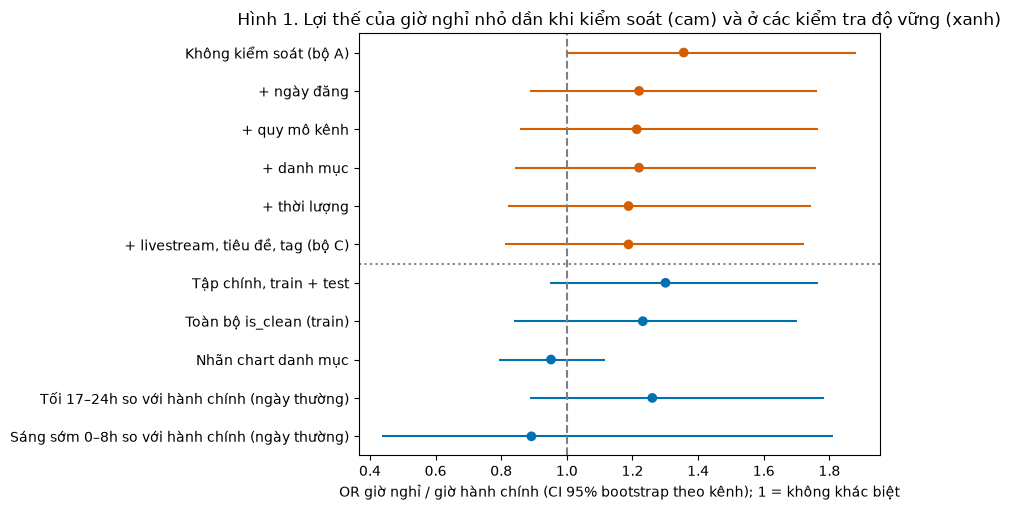

In [8]:
# Hình 1: OR của khung giờ ở mọi mức kiểm soát và mọi kiểm tra độ vững
hinh = pd.concat([
    tang_dan[["OR nghỉ / hành chính", "CI thấp", "CI cao"]].set_axis(["or", "lo", "hi"], axis=1),
    do_vung.set_index("Kiểm tra")[["OR", "CI thấp", "CI cao"]].set_axis(["or", "lo", "hi"], axis=1),
])
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(hinh))[::-1]
mau = ["#D55E00"] * len(tang_dan) + ["#0072B2"] * len(do_vung)
ax.errorbar(hinh["or"], y, xerr=[hinh["or"] - hinh["lo"], hinh["hi"] - hinh["or"]], fmt="o", ecolor=mau, color="none")
ax.scatter(hinh["or"], y, c=mau, zorder=3)
ax.axvline(1, ls="--", color="grey")
ax.axhline(len(do_vung) - 0.5, ls=":", color="grey")
ax.set_yticks(y); ax.set_yticklabels(hinh.index)
ax.set_xlabel("OR giờ nghỉ / giờ hành chính (CI 95% bootstrap theo kênh); 1 = không khác biệt")
ax.set_title("Hình 1. Lợi thế của giờ nghỉ nhỏ dần khi kiểm soát (cam) và ở các kiểm tra độ vững (xanh)")
plt.tight_layout()

### 1.6 LR dùng để dự đoán: chọn tham số, ngưỡng, chấm tập test một lần

Phần này dùng LR như một mô hình phân loại để so với mô hình mốc và với XGBoost (Phần 3):
- `class_weight="balanced"` vì chỉ khoảng 3,9% video trending.
- Chọn `C` bằng `StratifiedGroupKFold(5)` theo kênh trên train, tiêu chí **PR-AUC trung bình**; làm riêng cho **bộ C** và **bộ B** (bỏ khung giờ) để đo khung giờ đóng góp bao nhiêu vào dự đoán.
- **Ngưỡng** phân loại chọn theo F1 trên dự đoán out-of-fold, không dùng tập test.
- Chỉ số theo handover mục 5. **Chọn mô hình bằng PR-AUC**; accuracy chỉ để so với mô hình mốc.

In [9]:
folds = lg.chia_fold(train)
bang_cv_C, C_tot_C, oof_C = lg.tinh_chinh_C(train, BO_C, folds=folds)
bang_cv_B, C_tot_B, oof_B = lg.tinh_chinh_C(train, BO_B_LR, folds=folds)
nguong_C, nguong_B = lg.chon_nguong(y_train, oof_C), lg.chon_nguong(y_train, oof_B)
print(f"Bộ C: C tốt nhất = {C_tot_C}, ngưỡng = {nguong_C:.3f} | Bộ B: C tốt nhất = {C_tot_B}, ngưỡng = {nguong_B:.3f}")
pd.concat([bang_cv_C.assign(bo="C: có khung giờ"), bang_cv_B.assign(bo="B: không khung giờ")]).set_index(["bo", "C"]).round(4)

Bộ C: C tốt nhất = 0.03, ngưỡng = 0.748 | Bộ B: C tốt nhất = 0.03, ngưỡng = 0.725


pr_auc_tb  pr_auc_min  pr_auc_max
bo                 C                                       
C: có khung giờ    0.01      0.2039      0.1005      0.3067
                   0.03      0.2060      0.0999      0.3177
                   0.10      0.1993      0.0982      0.3112
                   0.30      0.1971      0.0977      0.3080
                   1.00      0.1941      0.0970      0.3007
                   3.00      0.1927      0.0969      0.2961
                   10.00     0.1920      0.0971      0.2944
B: không khung giờ 0.01      0.2074      0.0990      0.3125
                   0.03      0.2079      0.1001      0.3126
                   0.10      0.2072      0.0996      0.3121
                   0.30      0.2034      0.0995      0.3061
                   1.00      0.2004      0.0990      0.3069
                   3.00      0.1978      0.0988      0.2953
                   10.00     0.1979      0.0989      0.2957

In [10]:
# Khung giờ đóng góp bao nhiêu vào dự đoán: chênh lệch PR-AUC của bộ C và bộ B trên cùng fold
pr_C = lg.pr_auc_tung_fold(train, BO_C, C_tot_C, folds=folds)
pr_B = lg.pr_auc_tung_fold(train, BO_B_LR, C_tot_B, folds=folds)
delta = pd.DataFrame({"fold": range(1, 6), "PR-AUC bộ C": pr_C, "PR-AUC bộ B": pr_B, "chênh lệch C − B": pr_C - pr_B})
print(f"ΔPR-AUC trung bình = {np.mean(pr_C - pr_B):+.4f}, từ {np.min(pr_C - pr_B):+.4f} tới {np.max(pr_C - pr_B):+.4f}")
delta.round(4)

ΔPR-AUC trung bình = -0.0018, từ -0.0128 tới +0.0052


,fold,PR-AUC bộ C,PR-AUC bộ B,chênh lệch C − B
0,1,0.2108,0.2160,-0.0053
1,2,0.0999,0.1001,-0.0001
2,3,0.1095,0.1056,0.0039
3,4,0.3177,0.3126,0.0052
4,5,0.2923,0.3050,-0.0128


In [11]:
# Chấm tập test ĐÚNG MỘT LẦN, với tham số và ngưỡng đã chốt ở trên
mo_hinh_C = lg.ong_du_doan(BO_C, C_tot_C).fit(train[BO_C], y_train)
mo_hinh_B = lg.ong_du_doan(BO_B_LR, C_tot_B).fit(train[BO_B_LR], y_train)
p_test_C = mo_hinh_C.predict_proba(test[BO_C])[:, 1]
p_test_B = mo_hinh_B.predict_proba(test[BO_B_LR])[:, 1]

ket_qua_test = lg.mo_hinh_moc(y_train, y_test)
ket_qua_test["LR bộ B: không khung giờ"] = lg.chi_so(y_test, p_test_B, nguong_B)
ket_qua_test["LR bộ C: có khung giờ"] = lg.chi_so(y_test, p_test_C, nguong_C)
bang_test = pd.DataFrame(ket_qua_test).T
bang_test.round(4)

,accuracy,precision,recall,f1,pr_auc,roc_auc,prec_top1pct,prec_top5pct,tn,fp,fn,tp,nguong
Mốc: luôn đoán không trending,0.9625,0.0000,0.0000,0.0000,0.0375,0.5000,0.0476,0.0288,2001.0,0.0,78.0,0.0,0.5000
Mốc: ngẫu nhiên theo tỉ lệ,0.9211,0.0114,0.0128,0.0120,0.0372,0.4847,0.0000,0.0096,1914.0,87.0,77.0,1.0,0.5000
LR bộ B: không khung giờ,0.9038,0.1412,0.3077,0.1935,0.1512,0.8086,0.1905,0.1538,1855.0,146.0,54.0,24.0,0.7252
LR bộ C: có khung giờ,0.9168,0.1481,0.2564,0.1878,0.1538,0.8110,0.2381,0.1346,1886.0,115.0,58.0,20.0,0.7484


In [12]:
# Lưu dự đoán trên tập test để duc ghép vào bảng so sánh với XGBoost
du_doan = test[["video_id", "channel_id"]].assign(
    y=y_test, p_lr_c=p_test_C, p_lr_b=p_test_B,
    du_doan_lr_c=(p_test_C >= nguong_C).astype(int), nguong_lr_c=round(nguong_C, 4))
file_du_doan = ROOT / "data" / "processed" / "lr_test_predictions.csv"
du_doan.to_csv(file_du_doan, index=False)
print("Đã ghi", file_du_doan, du_doan.shape)

Đã ghi D:\Project\BanNH_QE210137_TRENDING_ANALYTICS\data\processed\lr_test_predictions.csv (2079, 7)


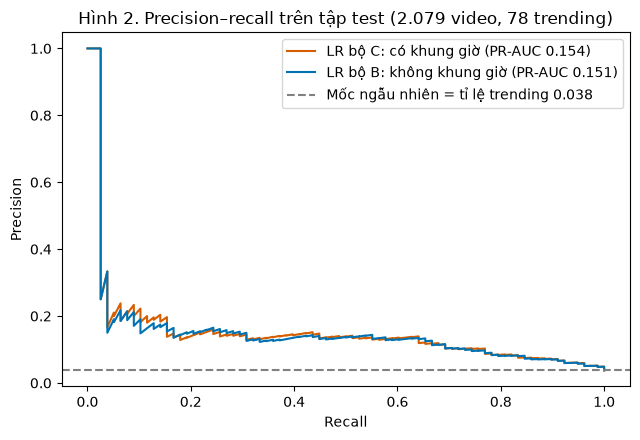

In [13]:
# Hình 2: đường precision–recall trên tập test
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for ten, p, mau in [("LR bộ C: có khung giờ", p_test_C, "#D55E00"), ("LR bộ B: không khung giờ", p_test_B, "#0072B2")]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, color=mau, label=f"{ten} (PR-AUC {lg.chi_so(y_test, p, 0.5)['pr_auc']:.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Mốc ngẫu nhiên = tỉ lệ trending {y_test.mean():.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(loc="upper right")
ax.set_title("Hình 2. Precision–recall trên tập test (2.079 video, 78 trending)")
plt.tight_layout()

### 1.7 Kết luận của phần Logistic Regression

Áp đúng quy tắc đã chốt trước khi chạy:

In [14]:
r = or_C.loc["time_slot_nghi"]
bac_bo = r["ci_thap"] > 1 or r["ci_cao"] < 1
print("OR giờ nghỉ / giờ hành chính, bộ C:", lg.dong_or(or_C))
print("OR thô, bộ A:", lg.dong_or(or_A))
print("Kết luận theo quy tắc:", "BÁC BỎ H₀" if bac_bo else "CHƯA ĐỦ BẰNG CHỨNG BÁC BỎ H₀")
print("Các kiểm tra độ vững có CI chứa 1:", ", ".join(do_vung.index[(do_vung["CI thấp"] <= 1) & (do_vung["CI cao"] >= 1)]) or "không có")
print(f"Khung giờ thêm vào dự đoán: ΔPR-AUC = {np.mean(pr_C - pr_B):+.4f} (CV), "
      f"{bang_test.loc['LR bộ C: có khung giờ', 'pr_auc'] - bang_test.loc['LR bộ B: không khung giờ', 'pr_auc']:+.4f} (test)")

OR giờ nghỉ / giờ hành chính, bộ C: 1,19 (0,81–1,72)
OR thô, bộ A: 1,36 (1,00–1,88)
Kết luận theo quy tắc: CHƯA ĐỦ BẰNG CHỨNG BÁC BỎ H₀
Các kiểm tra độ vững có CI chứa 1: R1, R2, R3, R4a, R4b
Khung giờ thêm vào dự đoán: ΔPR-AUC = -0.0018 (CV), +0.0027 (test)


*(Diễn giải chi tiết các con số ở trên: `docs/analysis/04_modeling.md`, mục M3–M6.)*

## Phần 2 — XGBoost (phat: huấn luyện; duc: giải thích)

Chạy ở hai notebook riêng, cùng `train` / `test` và cùng fold với Phần 1: `notebooks/2_Modeling_phat_XGB.ipynb` (tinh chỉnh, `src/modeling/model.py`) và `notebooks/2_Modeling_XGBoost.ipynb` (giải thích và so sánh, `src/modeling/xgb_eval.py`). Ô dưới đọc lại bộ tham số đã chốt; các số còn lại chép từ hai notebook đó (chi tiết: `docs/analysis/04_modeling.md` M7–M8).

**Huấn luyện (phat).** Lưới 48 tổ hợp, chọn theo PR-AUC trung bình trên 5 fold theo kênh, `scale_pos_weight` tính trong từng fold (≈ 25). Tham số chốt: `max_depth 4`, `learning_rate 0,03`, `n_estimators 200`, `min_child_weight 5`, `subsample 0,8`; PR-AUC CV **0,240 ± 0,083**, ROC-AUC 0,834; ngưỡng F1 0,777. Cả 48 tổ hợp nằm trong 1 độ lệch chuẩn của tổ hợp tốt nhất: kết quả không phụ thuộc cấu hình.

In [15]:
import json
tham_so = json.loads((ROOT / "data" / "processed" / "xgb_best_params.json").read_text(encoding="utf-8"))
print("Bộ tham số XGBoost đã chốt (phat):")
for k, v in tham_so.items():
    print(f"  {k}: {v}")

Bộ tham số XGBoost đã chốt (phat):
  feature_set: C
  model_type: tree
  random_state: 42
  best_params: {'max_depth': 4, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_weight': 5, 'subsample': 0.8}
  threshold: 0.7773813009262085
  pr_auc_cv_mean: 0.23984379689936555
  pr_auc_cv_std: 0.08263589264960004
  scale_pos_weight_note: tính lại trong từng fold: số nhãn 0 / số nhãn 1


**Có / bỏ biến thời gian (duc).** Cùng fold, cùng tham số:

| Fold | PR-AUC bộ C | PR-AUC bộ C bỏ 5 cột thời gian | Chênh lệch |
|---:|---:|---:|---:|
| 0 | 0,269 | 0,280 | −0,011 |
| 1 | 0,145 | 0,147 | −0,003 |
| 2 | 0,157 | 0,137 | +0,020 |
| 3 | 0,367 | 0,276 | +0,091 |
| 4 | 0,228 | 0,215 | +0,012 |
| **Trung bình** | **0,233** | **0,211** | **+0,022** (độ lệch chuẩn 0,041; 3/5 fold dương) |

**Permutation importance (duc, validation của CV, 10 lần hoán vị):** danh mục 0,141 · thời lượng 0,076 · quy mô kênh 0,072 · NHÓM thời gian (5 cột) 0,031, trong đó `publish_hour_vn` 0,029 và **`time_slot` −0,0005** · số tag 0,015 · ngày đăng 0,008 · livestream 0,006 · độ dài tiêu đề 0,002.

**Ổn định theo thời gian (duc):** train đợt 1 (6.054 video, 266 trending), test đợt 2 (2.098 video, 49 trending), bỏ biến ngày đăng: PR-AUC 0,262, ROC-AUC 0,912, recall 0,612, precision 0,201 (mốc PR-AUC 0,023).

## Phần 3 — So sánh mô hình trên tập test (duc)

Mỗi mô hình chấm đúng một lần; dòng LR lấy từ `data/processed/lr_test_predictions.csv` (mục 1.6), khớp theo `video_id`.

| Mô hình | Accuracy | Precision | Recall | F1 | PR-AUC | ROC-AUC | P@1% | P@5% | TP / FP / FN |
|---|---|---|---|---|---|---|---|---|---|
| Mốc: luôn đoán "không" | 0,963 | 0 | 0 | 0 | 0,038 | 0,500 | 0,048 | 0,029 | 0 / 0 / 78 |
| Mốc: ngẫu nhiên theo tỉ lệ | 0,921 | 0,011 | 0,013 | 0,012 | 0,037 | 0,485 | 0 | 0,010 | 1 / 87 / 77 |
| LR bộ C | 0,917 | 0,148 | 0,256 | 0,188 | 0,154 | 0,811 | 0,238 | 0,135 | 20 / 115 / 58 |
| **XGBoost bộ C** | 0,949 | **0,296** | 0,269 | **0,282** | **0,228** | **0,868** | **0,381** | **0,250** | 21 / 50 / 57 |

XGBoost tốt hơn LR ở mọi chỉ số xếp hạng (PR-AUC 0,228 so với 0,154, gấp 6 lần mốc); cùng recall khoảng 0,26 nhưng báo nhầm ít hơn một nửa. Accuracy cao nhất thuộc mô hình luôn đoán "không" (96,3%) nên không dùng để so.

## Phần 4 — Kết luận chung (BanNH)

Áp đúng quy tắc chốt trước khi chạy:

1. **Chưa đủ bằng chứng bác bỏ H₀.** OR giờ nghỉ / giờ hành chính của LR bộ C là **1,19 (CI 95% 0,81–1,72)**, CI chứa 1; 5 kiểm tra độ vững đều chứa 1.
2. **Kết luận vững theo XGBoost.** `time_slot` có importance ≈ 0, cùng chiều với LR. Bỏ cả nhóm thời gian làm PR-AUC giảm 0,022 nhưng mức giảm nằm trong biên độ nhiễu giữa các fold và nhỏ hơn 2–5 lần so với danh mục, thời lượng, quy mô kênh; phần tín hiệu còn lại là giờ đăng chi tiết (khớp đỉnh 16–18h ở EDA), không phải khung hành chính / nghỉ.
3. **Hai mô hình bổ sung cho nhau:** LR trả lời H₀ bằng OR có khoảng tin cậy; XGBoost dự đoán tốt hơn và ổn định theo thời gian, xác nhận chiều của LR.
4. **Yếu tố quyết định** là loại video (thể loại, thời lượng, quy mô kênh), không phải giờ đăng. Trong phạm vi dữ liệu này không có "thời điểm vàng" theo nghĩa giờ hành chính so với giờ nghỉ.

Giới hạn: dữ liệu quan sát; 315 video trending trên train, 78 trên test nên khoảng tin cậy rộng (không loại trừ lợi thế tới 1,7 lần); tập sạch 14 ngày của các kênh đang theo dõi; Shorts ước lượng theo thời lượng. Báo cáo đầy đủ: `reports/Report_4_Modeling.pdf`.